# Projet 6 — Algorithme EM pour un mélange de Gaussiennes

Reproduction des expériences de [EE 227C, Lecture 19, section EM](https://ee227c.github.io/code/lecture19.html#em)
(mélange de deux Gaussiennes en dimension 1, puis *k-means*) et étude de l'influence des paramètres : initialisation,
séparation des composantes, taille d'échantillon et nombre de composantes $K$. Application aux données Iris.

In [1]:
import os
import numpy as np, matplotlib.pyplot as plt
from scipy.special import logsumexp
np.random.seed(1); rng = np.random.default_rng(1)

def save(name):  # figures pour le rapport LaTeX
    if os.path.isdir('Rapport/Figures'): plt.savefig(f'Rapport/Figures/{name}.png', dpi=150, bbox_inches='tight')

## 1. L'algorithme EM

Modèle : $z_i\in\{1,\dots,K\}$ caché avec $P(z_i=k)=\pi_k$, et $x_i\mid z_i=k\sim\mathcal N(\mu_k,\sigma_k^2)$.
On maximise la log-vraisemblance (non concave)
$$L(\theta)=\sum_{i=1}^n\log\sum_{k=1}^K\pi_k\,\varphi(x_i;\mu_k,\sigma_k^2),\qquad \theta=(\pi,\mu,\sigma).$$

* **E (espérance)** : probabilités a posteriori
  $t_{ik}=P_{\theta}(z_i=k\mid x_i)=\dfrac{\pi_k\varphi(x_i;\mu_k,\sigma_k^2)}{\sum_j\pi_j\varphi(x_i;\mu_j,\sigma_j^2)}$
  (calculées en échelle log avec *log-sum-exp*) ;
* **M (maximisation)** : avec $n_k=\sum_it_{ik}$,
  $\pi_k=\dfrac{n_k}{n},\quad \mu_k=\dfrac{\sum_it_{ik}x_i}{n_k},\quad \sigma_k^2=\dfrac{\sum_it_{ik}(x_i-\mu_k)^2}{n_k}.$

EM est une **maximisation alternée** de $G(Q,\theta)=\sum_{i,k}t_{ik}\log p_\theta(x_i,k)-\sum_{i,k}t_{ik}\log t_{ik}$,
qui vaut $L(\theta)$ après l'étape E : la log-vraisemblance **ne décroît jamais**, mais EM peut converger vers un
maximum local ou un point selle.

In [2]:
def em(e, m, X, theta, steps, tol=None):
    # Boucle EM de Berkeley (arrêt optionnel si la log-vraisemblance varie de moins de tol)
    thetas = [theta]
    for _ in range(steps):
        Q = e(X, theta)
        theta = m(Q, X)
        thetas.append(theta)
        if tol is not None and abs(gmm_likelihood(X, thetas[-1]) - gmm_likelihood(X, thetas[-2])) < tol:
            break
    return thetas

def gmm_joint(X, theta):
    # matrice n x K des log p_theta(x_i, z=k)
    pi, mu, sigma = theta
    diffs = np.subtract.outer(X, mu) / sigma
    return -0.5 * diffs ** 2 - 0.5 * np.log(2 * np.pi) - np.log(sigma) + np.log(pi)

def gmm_e(X, theta):
    joint = gmm_joint(X, theta)
    return np.exp(joint - logsumexp(joint, axis=1, keepdims=True))   # t_ik

def gmm_m(Q, X):
    nk = Q.sum(axis=0)
    pi = nk / nk.sum()
    mu = Q.T @ X / nk
    sigma2 = np.sum(Q * np.subtract.outer(X, mu) ** 2, axis=0) / nk
    return pi, mu, np.sqrt(sigma2)

def gmm_likelihood(X, theta):
    # Correction du code de Berkeley : logsumexp(joint) sans axe calcule log sum_i sum_k p(x_i, k),
    # alors que la log-vraisemblance est sum_i log sum_k p(x_i, k).
    return logsumexp(gmm_joint(X, theta), axis=1).sum()

## 2. Expérience de Berkeley
$n=4000$ points : moitié $\mathcal N(-2,1)$, moitié $\mathcal N(2,1)$. Initialisation des moyennes aux quartiles,
poids et écarts-types aléatoires.

poids [0.498 0.502]  moyennes [-2.022  1.989]  écarts-types [0.997 1.002]
log-vraisemblance croissante : True


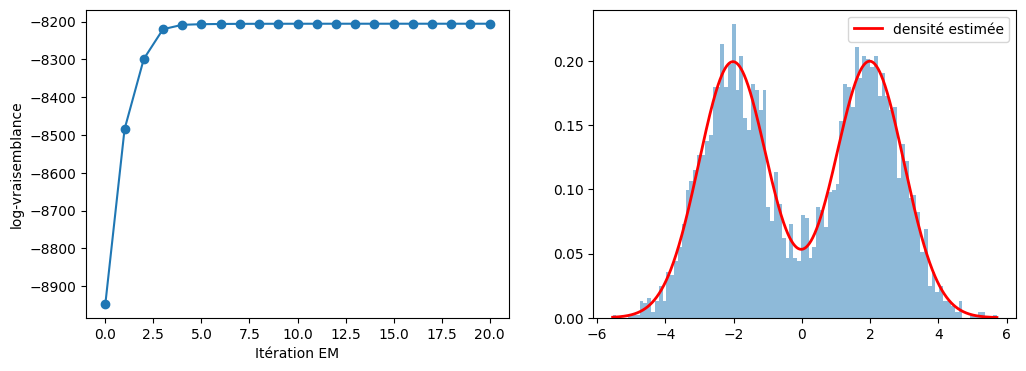

In [3]:
data = np.hstack([rng.normal(-2, 1, 2000), rng.normal(2, 1, 2000)])
pi1 = rng.uniform(0.25, 0.75)
theta0 = (np.array([pi1, 1 - pi1]), np.percentile(data, [25, 75]), rng.uniform(0.5, 2, size=2))
thetas = em(gmm_e, gmm_m, data, theta0, 20)
lik = [gmm_likelihood(data, t) for t in thetas]
pi, mu, sigma = thetas[-1]
print('poids', pi.round(3), ' moyennes', mu.round(3), ' écarts-types', sigma.round(3))
print('log-vraisemblance croissante :', bool(np.all(np.diff(lik) >= -1e-9)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(lik, 'o-'); ax[0].set(xlabel='Itération EM', ylabel='log-vraisemblance')
ax[1].hist(data, bins=100, density=True, alpha=.5)
xs = np.linspace(data.min(), data.max(), 1000)
ax[1].plot(xs, np.exp(gmm_joint(xs, thetas[-1])).sum(1), 'r', lw=2, label='densité estimée')
ax[1].legend(); save('berkeley_em'); plt.show()

## 3. Influence des paramètres

### 3.1 Initialisation
Berkeley note que l'initialisation des moyennes est importante. On compare 20 initialisations aléatoires (moyennes
tirées parmi les données) à l'initialisation par quartiles, et on teste une initialisation **symétrique**
($\mu_1=\mu_2$, $\sigma_1=\sigma_2$, $\pi_1=\pi_2$) : les deux composantes restent alors identiques à chaque itération
(point selle), et EM ne peut pas séparer les groupes.

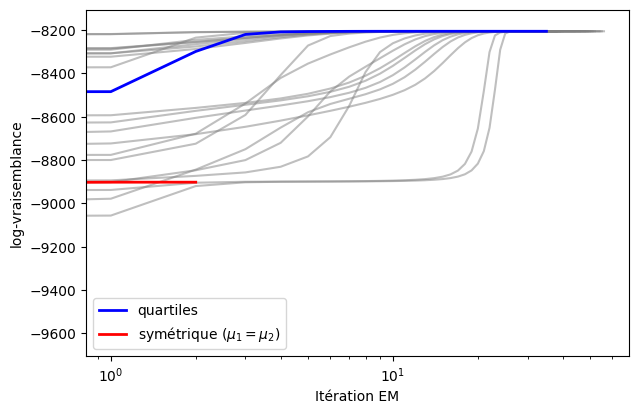

20 init. aléatoires : log-vrais. finale min -8205.58 / max -8205.58 ; itérations médiane 42 (min 33, max 56)
quartiles : log-vrais. -8205.58 , 35 itérations
symétrique : moyennes finales [-0.01 -0.01] , log-vrais. -8902.4


In [4]:
def run(X, theta, steps=500, tol=1e-8):
    th = em(gmm_e, gmm_m, X, theta, steps, tol)
    return th, [gmm_likelihood(X, t) for t in th]

fig, ax = plt.subplots(figsize=(7, 4.5))
finals = []
for r in range(20):
    th0 = (np.array([.5, .5]), rng.choice(data, 2, replace=False), rng.uniform(0.5, 2, 2))
    th, l = run(data, th0); finals.append((l[-1], len(l) - 1)); ax.plot(l, color='grey', alpha=.5)
th, l = run(data, theta0); ax.plot(l, 'b', lw=2, label='quartiles')
th_sym, l_sym = run(data, (np.array([.5, .5]), np.array([0.3, 0.3]), np.array([1., 1.])))
ax.plot(l_sym, 'r', lw=2, label='symétrique ($\\mu_1=\\mu_2$)')
ax.set(xscale='log', xlabel='Itération EM', ylabel='log-vraisemblance', ylim=(l[-1] - 1500, l[-1] + 100)); ax.legend()
save('initialisation'); plt.show()
f = np.array(finals)
print(f'20 init. aléatoires : log-vrais. finale min {f[:, 0].min():.2f} / max {f[:, 0].max():.2f} ; '
      f'itérations médiane {np.median(f[:, 1]):.0f} (min {f[:, 1].min():.0f}, max {f[:, 1].max():.0f})')
print('quartiles : log-vrais.', round(l[-1], 2), ',', len(l) - 1, 'itérations')
print('symétrique : moyennes finales', th_sym[-1][1].round(3), ', log-vrais.', round(l_sym[-1], 2))

### 3.2 Séparation des composantes
Moyennes $\pm\Delta/2$, variances 1, $n=4000$. Plus les composantes se recouvrent, plus l'« information manquante »
($z_i$) est importante et plus EM converge **lentement** (convergence linéaire de taux proche de 1).

Delta = 1 : 2000 itérations ; moyennes estimées [-0.58  0.52]
Delta = 2 : 1472 itérations ; moyennes estimées [-0.89  1.08]
Delta = 3 :  142 itérations ; moyennes estimées [-1.58  1.43]
Delta = 4 :   34 itérations ; moyennes estimées [-1.98  2.  ]


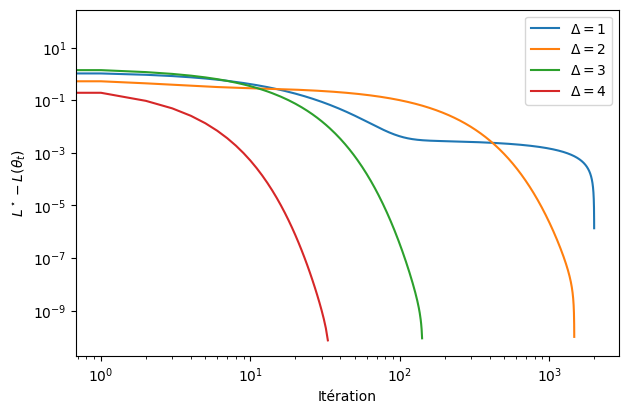

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for d in [1, 2, 3, 4]:
    X = np.hstack([rng.normal(-d / 2, 1, 2000), rng.normal(d / 2, 1, 2000)])
    th, l = run(X, (np.array([.5, .5]), np.percentile(X, [25, 75]), np.array([1., 1.])), steps=2000, tol=1e-10)
    ax.plot(np.array(l[-1]) - np.array(l[:-1]) + 1e-12, label=f'$\\Delta={d}$')
    print(f'Delta = {d} : {len(th) - 1:4d} itérations ; moyennes estimées {th[-1][1].round(2)}')
ax.set(yscale='log', xscale='log', xlabel='Itération', ylabel='$L^\\star-L(\\theta_t)$'); ax.legend()
save('separation'); plt.show()

### 3.3 Taille d'échantillon
Erreur d'estimation des moyennes (vraies valeurs $\pm2$) en fonction de $n$, moyennée sur 20 répétitions :
l'erreur statistique décroît en $1/\sqrt n$ (l'optimisation ne peut pas faire mieux).

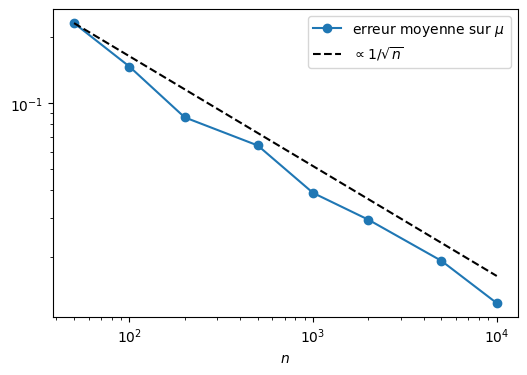

In [6]:
ns = [50, 100, 200, 500, 1000, 2000, 5000, 10000]
err = []
for n in ns:
    e = []
    for _ in range(20):
        X = np.hstack([rng.normal(-2, 1, n // 2), rng.normal(2, 1, n // 2)])
        th, _ = run(X, (np.array([.5, .5]), np.percentile(X, [25, 75]), np.array([1., 1.])))
        e.append(np.abs(np.sort(th[-1][1]) - [-2, 2]).mean())
    err.append(np.mean(e))
plt.figure(figsize=(6, 4))
plt.loglog(ns, err, 'o-', label='erreur moyenne sur $\\mu$')
plt.loglog(ns, err[0] * np.sqrt(ns[0] / np.array(ns)), 'k--', label='$\\propto 1/\\sqrt{n}$')
plt.xlabel('$n$'); plt.legend(); save('taille_echantillon'); plt.show()

### 3.4 Nombre de composantes $K$
La log-vraisemblance augmente toujours avec $K$ (modèles emboîtés) : on choisit $K$ avec le critère
$\mathrm{BIC}=-2L+(3K-1)\log n$ (à minimiser). Initialisation des moyennes aux quantiles.

In [7]:
def fit_k(X, K, steps=1000):
    q = np.percentile(X, np.linspace(0, 100, K + 2)[1:-1])
    th, l = run(X, (np.full(K, 1 / K), q, np.full(K, X.std())), steps=steps)
    return th[-1], l[-1]

def bic_table(X, Ks=range(1, 6)):
    res = [(K,) + fit_k(X, K) for K in Ks]
    for K, th, L in res:
        print(f'K = {K} : log-vrais. = {L:9.2f}   BIC = {-2 * L + (3 * K - 1) * np.log(len(X)):9.2f}')
    return res

res = bic_table(data)

K = 1 : log-vrais. =  -8902.40   BIC =  17821.39
K = 2 : log-vrais. =  -8205.58   BIC =  16452.64
K = 3 : log-vrais. =  -8204.63   BIC =  16475.61
K = 4 : log-vrais. =  -8204.60   BIC =  16500.42
K = 5 : log-vrais. =  -8204.65   BIC =  16525.41


## 4. *k-means* (fin de la section de Berkeley)
Exemple de J. VanderPlas : 4 groupes en dimension 2. *k-means* est la limite de EM pour un mélange de Gaussiennes
sphériques de même variance $\sigma^2\to0$ (affectations « dures » au lieu des $t_{ik}$). On compare à un mélange de
Gaussiennes ajusté par EM (`GaussianMixture`, version multivariée de notre algorithme).

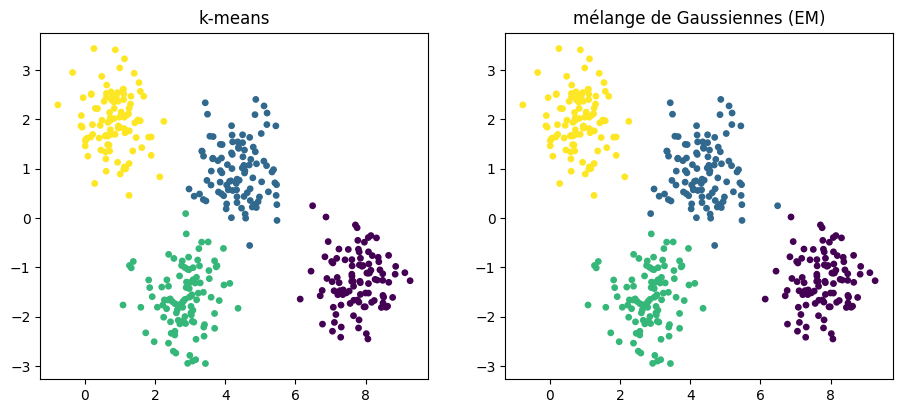

In [8]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
Xb, yb = make_blobs(n_samples=400, centers=4, cluster_std=0.60, random_state=0); Xb = Xb[:, ::-1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(Xb[:, 0], Xb[:, 1], c=KMeans(4, random_state=0, n_init=10).fit_predict(Xb), s=15); ax[0].set_title('k-means')
ax[1].scatter(Xb[:, 0], Xb[:, 1], c=GaussianMixture(4, random_state=0).fit(Xb).predict(Xb), s=15); ax[1].set_title('mélange de Gaussiennes (EM)')
save('kmeans'); plt.show()

## 5. Données réelles : longueur des pétales (Iris)
La longueur des pétales des 150 iris est bimodale (*setosa* d'un côté, *versicolor* et *virginica* de l'autre).
On choisit $K$ par BIC puis on compare avec `GaussianMixture` de scikit-learn.

K = 1 : log-vrais. =   -297.59   BIC =    605.20
K = 2 : log-vrais. =   -200.58   BIC =    426.21
K = 3 : log-vrais. =   -199.80   BIC =    439.68
K = 4 : log-vrais. =   -199.79   BIC =    454.70
K = 5 : log-vrais. =   -199.78   BIC =    469.72
K retenu : 2 ; poids [0.333 0.667] ; moyennes [1.462 4.905] ; écarts-types [0.172 0.823]
scikit-learn : poids [0.667 0.333] ; moyennes [4.905 1.462]
Groupes x espèces :
 [[50  0  0]
 [ 0 50 50]]


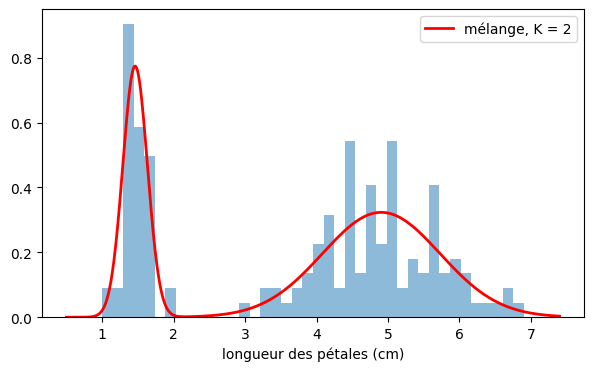

In [9]:
from sklearn.datasets import load_iris
iris = load_iris(); petal = iris.data[:, 2]
res = bic_table(petal)
K_best = min(res, key=lambda r: -2 * r[2] + (3 * r[0] - 1) * np.log(len(petal)))[0]
th_best = [r[1] for r in res if r[0] == K_best][0]
print('K retenu :', K_best, '; poids', th_best[0].round(3), '; moyennes', th_best[1].round(3), '; écarts-types', th_best[2].round(3))
sk = GaussianMixture(K_best, random_state=0).fit(petal[:, None])
print('scikit-learn : poids', sk.weights_.round(3), '; moyennes', sk.means_.ravel().round(3))
z = gmm_e(petal, th_best).argmax(1)
print('Groupes x espèces :\n', np.array([[np.sum((z == k) & (iris.target == s)) for s in range(3)] for k in range(K_best)]))

plt.figure(figsize=(7, 4))
plt.hist(petal, bins=40, density=True, alpha=.5)
xs = np.linspace(petal.min() - .5, petal.max() + .5, 500)
plt.plot(xs, np.exp(gmm_joint(xs, th_best)).sum(1), 'r', lw=2, label=f'mélange, K = {K_best}')
plt.xlabel('longueur des pétales (cm)'); plt.legend(); save('iris'); plt.show()

## Conclusion
* La log-vraisemblance croît à chaque itération ; l'expérience de Berkeley retrouve $\mu\approx(-2;2)$ et $\sigma\approx(1;1)$.
* Les 20 initialisations aléatoires mènent au même maximum ; l'initialisation symétrique reste bloquée en un point selle (une seule Gaussienne).
* Plus les composantes se recouvrent, plus EM est lent (34 itérations pour $\Delta=4$, plus de 2000 pour $\Delta=1$).
* L'erreur sur les moyennes décroît en $1/\sqrt n$ ; le BIC retient $K=2$ sur les données simulées et sur les pétales d'Iris (setosa contre les deux autres espèces).